# Dataset Preparation and Fixed Split
**Project:** Emotion classification of Arabic (Egyptian) tweets with RNN models — a re-implementation of Glenn, LaCasse & Cox (2023), which used Indonesian tweets.

**This part :** produce *one* clean 5-emotion dataset and *one* fixed train / validation / test split that the whole team uses.

**What this notebook does, in order**
1. Load the original AETD file and inspect it
2. Clean column names and labels
3. Keep the 5 emotions (anger, joy, sadness, love, fear)
4. Remove empty tweets, exact duplicates and conflicting labels
5. Find extra duplicates that only appear after normalization (links, mentions, punctuation)
6. Compute statistics and make charts
7. Make the stratified 70/15/15 split and verify it
8. Save everything for the team

> Every number below is calculated from the file when the notebook runs. Nothing is typed in by hand.

## 1. Dataset source
**Arabic Egyptian Twitter Emotion Dataset (AETD)** — Al-Khatib & El-Beltagy (2017), CICLing 2017. Repository: https://github.com/amrmalkhatib/Emotional-Tone (file `Emotional-Tone-Dataset.csv`). The task sheet states 10,065 tweets in 8 classes; we check that below instead of trusting it.

## 2. Importing libraries and settings
The random seed is set **once**, here. It is the only number that controls the split, so it must never change after we hand the files to the team.

In [45]:

import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Fixed settings
SEED = 42
KEEP = ["anger", "joy", "sadness", "love", "fear"]
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

# Download dataset directly from GitHub
RAW_URL = "https://raw.githubusercontent.com/amrmalkhatib/Emotional-Tone/master/Emotional-Tone-Dataset.csv"

df = pd.read_csv(RAW_URL)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# Project directories
ROOT = Path("..") if Path("../data/raw").exists() else Path(".")

RAW = ROOT / "data" / "raw" / "Emotional-Tone-Dataset.csv"
OUT = ROOT / "data" / "processed"
STATS = ROOT / "stats"
FIGS = ROOT / "figures"

# Create all required directories
for p in (RAW.parent, OUT, STATS, FIGS):
    p.mkdir(parents=True, exist_ok=True)

# Save a local copy of the original dataset
df.to_csv(RAW, index=False)

print("\nDataset saved successfully at:", RAW)

# Cleaning log: one row per cleaning step
log = []

def record(step, df, prev):
    log.append({
        "step": step,
        "rows_after": len(df),
        "rows_removed": prev - len(df)
    })
    print(f"{step}: {len(df):,} rows (removed {prev - len(df):,})")



Dataset loaded successfully!
Shape: (10065, 3)

First 5 rows:
   ID                                              TWEET    LABEL
0   1            الاوليمبياد الجايه هكون لسه ف الكليه ..     none
1   2  عجز الموازنه وصل ل93.7 % من الناتج المحلي يعني...    anger
2   3                         كتنا نيله ف حظنا الهباب xD  sadness
3   4  جميعنا نريد تحقيق اهدافنا لكن تونس تالقت في حر...      joy
4   5  الاوليمبياد نظامها مختلف .. ومواعيد المونديال ...     none

Dataset saved successfully at: data/raw/Emotional-Tone-Dataset.csv


## 3. Loading the original dataset and first look

In [46]:
raw = pd.read_csv(RAW)
print("Shape:", raw.shape)
print("Column names (with repr, so hidden spaces are visible):", [repr(c) for c in raw.columns])
print()
print(raw.dtypes)

Shape: (10065, 3)
Column names (with repr, so hidden spaces are visible): ["'ID'", "' TWEET'", "' LABEL'"]

ID         int64
 TWEET    object
 LABEL    object
dtype: object


In [47]:
print("Missing values per column:")
print(raw.isna().sum())
print()
print("Label values as stored (repr shows any hidden spaces):")
print(raw.iloc[:, 2].map(repr).value_counts())
raw.head(8)

Missing values per column:
ID        0
 TWEET    1
 LABEL    0
dtype: int64

Label values as stored (repr shows any hidden spaces):
 LABEL
'none'        1550
'anger'       1444
'joy'         1281
'sadness'     1256
'love'        1220
'fear'        1207
'sympathy'    1062
'surprise'    1045
Name: count, dtype: int64


,ID,TWEET,LABEL
0,1,الاوليمبياد الجايه هكون لسه ف الكليه ..,none
1,2,عجز الموازنه وصل ل93.7 % من الناتج المحلي يعني...,anger
2,3,كتنا نيله ف حظنا الهباب xD,sadness
3,4,جميعنا نريد تحقيق اهدافنا لكن تونس تالقت في حر...,joy
4,5,الاوليمبياد نظامها مختلف .. ومواعيد المونديال ...,none
5,6,دلوقتي عندها اربع سنين .... ومحدش يقدر يكلمها ...,surprise
6,7,الحب يسلبها كيدها يرجعها الي براءتها الاولي وي...,love
7,8,she3er: شوفي بـ عيني امنيات الغلابه واحلام ثلث...,sympathy


## 4. Cleaning column names and labels
**What:** strip leading/trailing spaces from the column names and from the label values, and lower-case the labels.
**Why:** in the raw file the header is `ID, TWEET, LABEL`, so pandas reads the columns as `' TWEET'` and `' LABEL'` (with a leading space). Then `df['TWEET']` raises a `KeyError`. For labels, `'joy'` and `'joy '` are *different strings* to Python, so a filter or a `value_counts` would silently treat them as two classes.
**Honest check:** the task sheet says the label values also contain extra spaces. In *this* file the spaces are only in the column names, the labels are already clean. We still strip the labels, because it is harmless and protects us if the file is replaced.

In [48]:
df = raw.copy()
df.columns = df.columns.str.strip()
df["LABEL"] = df["LABEL"].astype(str).str.strip().str.lower()

print("Columns now:", list(df.columns))
print("Labels:", sorted(df["LABEL"].unique()))
assert df["LABEL"].nunique() == 8, "expected 8 labels in the original file"
assert df["ID"].is_unique, "IDs must be unique, we use them to check overlap later"
print("Total tweets:", len(df))
df["LABEL"].value_counts()

Columns now: ['ID', 'TWEET', 'LABEL']
Labels: ['anger', 'fear', 'joy', 'love', 'none', 'sadness', 'surprise', 'sympathy']
Total tweets: 10065


,count
LABEL,
none,1550
anger,1444
joy,1281
sadness,1256
love,1220
fear,1207
sympathy,1062
surprise,1045


## 5. Keeping the 5 emotions
We keep `anger, joy, sadness, love, fear` (the same five classes as the paper). `none`, `sympathy` and `surprise` are removed: the paper also removed no-emotion and multi-emotion tweets, and its models predict exactly these five classes.

In [49]:
prev = len(df)
df = df[df["LABEL"].isin(KEEP)].copy()
record("Keep 5 emotions", df, prev)
log.insert(0, {"step": "Original file", "rows_after": len(raw), "rows_removed": 0})
df["LABEL"].value_counts()

Keep 5 emotions: 6,408 rows (removed 3,657)


,count
LABEL,
anger,1444
joy,1281
sadness,1256
love,1220
fear,1207


## 6. Empty tweets
A tweet with no text gives the model nothing to learn from. We look for missing values *and* strings that are only whitespace.

In [50]:
blank = df["TWEET"].isna() | (df["TWEET"].fillna("").str.strip() == "")
print("Empty / missing tweets:", blank.sum())
print(df[blank])
prev = len(df)
df = df[~blank].copy()
record("Remove empty tweets", df, prev)

Empty / missing tweets: 1
        ID TWEET LABEL
8619  8620   NaN  love
Remove empty tweets: 6,407 rows (removed 1)


## 7. Exact duplicates vs. conflicting labels
- **Exact duplicate:** the same text appears more than once with the **same** label. It is redundant. We keep one copy.
- **Conflicting labels:** the same text appears with **different** labels. At least one annotation is wrong or the tweet is ambiguous, and we cannot know which. Keeping one copy at random would put a coin-flip label in the data, so we remove *all* copies.

Removing a duplicate without checking the labels first is the common mistake: `drop_duplicates('TWEET')` keeps an arbitrary label for the conflicting texts.

In [51]:
dup_mask = df.duplicated("TWEET", keep=False)
dups = df[dup_mask].sort_values(["TWEET", "ID"])
per_text = dups.groupby("TWEET")["LABEL"].nunique()
conflict_texts = per_text[per_text > 1].index
same_label_texts = per_text[per_text == 1].index

print("Texts that appear more than once:", len(per_text))
print(" - same label (exact duplicates):", len(same_label_texts))
print(" - different labels (conflicts):  ", len(conflict_texts))
print()
print("The conflicting texts, with their labels:")
conf = dups[dups["TWEET"].isin(conflict_texts)].copy()
conf["TWEET"] = conf["TWEET"].str.slice(0, 60)
conf

Texts that appear more than once: 15
 - same label (exact duplicates): 10
 - different labels (conflicts):   5

The conflicting texts, with their labels:


,ID,TWEET,LABEL
5538,5539,2016: شخصيه الاسبوع الملك عبدالله بن عبدالعز...,love
9723,9724,2016: شخصيه الاسبوع الملك عبدالله بن عبدالعز...,joy
4738,4739,22 حمدين صباحي حيموت علي الرياسه ياعيني كل ش...,joy
8634,8635,22 حمدين صباحي حيموت علي الرياسه ياعيني كل ش...,anger
720,721,: اليوم العالمي للشباب الامم المتحده تمنح جائ...,joy
1449,1450,: اليوم العالمي للشباب الامم المتحده تمنح جائ...,love
2602,2603,: لعب من اجل النصر! اعطي من اجل النصر! ضحّي من...,joy
2826,2827,: لعب من اجل النصر! اعطي من اجل النصر! ضحّي من...,love
7214,7215,يلاحظ في مقدمه الرساله ونهايتها اطراء جم لعلما...,joy
8019,8020,يلاحظ في مقدمه الرساله ونهايتها اطراء جم لعلما...,love


In [52]:
# 1) conflicts: remove every copy
prev = len(df)
df = df[~df["TWEET"].isin(conflict_texts)].copy()
record("Remove conflicting-label texts (all copies)", df, prev)

# 2) exact duplicates: keep the first copy (lowest ID, so the choice is deterministic)
prev = len(df)
df = df.sort_values("ID").drop_duplicates("TWEET", keep="first").copy()
record("Remove exact duplicates (keep lowest ID)", df, prev)

Remove conflicting-label texts (all copies): 6,397 rows (removed 10)
Remove exact duplicates (keep lowest ID): 6,387 rows (removed 10)


## 8. Near-duplicates after normalization
Two tweets can differ only by a link, a @mention or punctuation, and still be "the same tweet". If one lands in train and the other in test, the model has effectively seen the test tweet: **data leakage**.



In [53]:
!pip install emoji
import emoji

In [54]:
URL_RE = re.compile(
    r"(?:https?://\S+|www\.\S+|\[URL\])",
    flags=re.IGNORECASE
)
MENTION_RE = re.compile(r"(?:@\w+|\[USERNAME\])")
DIACRITICS_RE = re.compile(
    r"[\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06ED]"
)
PUNCT_RE = re.compile(r"[^\w\s]", flags=re.UNICODE)
NUMBERS_RE = re.compile(r"\d+")
ALEF_RE = re.compile(r"[أإآ]")
REPEATED_RE = re.compile(r"(.)\1{2,}", flags=re.UNICODE)

def normalize_for_dedup(text):
    text = str(text)
    # 1. Remove URLs
    text = URL_RE.sub("", text)
    # 2. Remove mentions
    text = MENTION_RE.sub("", text)
    # 3. Remove hashtag symbol but keep the word
    text = text.replace("#", "")
    # 4. Remove emojis
    text = emoji.replace_emoji(text, replace="")
    # 5. Remove Arabic diacritics and tatweel
    text = DIACRITICS_RE.sub("", text)
    text = text.replace("ـ", "")
    # 6. Normalize Alef
    text = ALEF_RE.sub("ا", text)
    # 7. Remove numbers
    text = NUMBERS_RE.sub("", text)
    # 8. Reduce repeated characters (3+ to 1)
    text = REPEATED_RE.sub(r"\1", text)
    # 9. Remove punctuation and symbols
    text = PUNCT_RE.sub("", text)
    # 10. Normalize spaces
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Normalize tweets FIRST
df["norm"] = df["TWEET"].fillna("").map(normalize_for_dedup)

# Check cleaning
print("Tweets containing a link:", df["TWEET"].str.contains(URL_RE, na=False).sum())
print("Tweets containing a mention:", df["TWEET"].str.contains(MENTION_RE, na=False).sum())
print("Tweets containing emojis:",
      df["TWEET"].apply(lambda x: emoji.emoji_count(str(x)) > 0).sum())
print("Tweets that become empty:", (df["norm"] == "").sum())

Tweets containing a link: 0
Tweets containing a mention: 0
Tweets containing emojis: 1249
Tweets that become empty: 2


This dataset has no links or mentions left, so the near-duplicates come from **punctuation and Arabic diacritics**. Tweets made only of punctuation or an emoji have no usable text once normalized, so we remove them before looking for duplicates (otherwise they would all count as duplicates of each other).

In [55]:
# Remove empty tweets
prev = len(df)
df = df[df["norm"] != ""].copy()
record("Remove tweets with no text after normalization", df, prev)

# Identify duplicate groups and conflicting labels
counts = df["norm"].value_counts()
grp = df.groupby("norm")["LABEL"].nunique()

print("Normalized texts appearing more than once:", (counts > 1).sum())
print("Conflicting normalized texts:", (grp > 1).sum())

# Remove all copies of conflicting groups
conflict_norm = grp[grp > 1].index

prev = len(df)
df = df[~df["norm"].isin(conflict_norm)].copy()
record("Remove near-duplicate conflicts", df, prev)

# Keep one copy of each remaining normalized tweet
prev = len(df)
df = df.sort_values("ID").drop_duplicates("norm", keep="first").copy()
record("Remove near-duplicates", df, prev)


Remove tweets with no text after normalization: 6,385 rows (removed 2)
Normalized texts appearing more than once: 51
Conflicting normalized texts: 0
Remove near-duplicate conflicts: 6,385 rows (removed 0)
Remove near-duplicates: 6,331 rows (removed 54)


In [56]:
# Show examples using original data
before_norm = raw.copy()
before_norm.columns = before_norm.columns.str.strip()
before_norm["norm"] = before_norm["TWEET"].fillna("").map(normalize_for_dedup)

ex = before_norm[
    before_norm.duplicated("norm", keep=False)
    & ~before_norm.duplicated("TWEET", keep=False)
    & (before_norm["norm"] != "")
]

ex = ex[
    ex["LABEL"].str.strip().isin(KEEP)
].sort_values("norm").head(6)

ex[["ID", "TWEET", "LABEL"]].reset_index(drop=True)

,ID,TWEET,LABEL
0,9835,shosho اني عكسكم خايفه 😶,fear
1,8189,: shosho اني عكسكم خايفه 😶,fear
2,6295,اسمي المشاعر والاحاسيس يشعر بها الانسان تجاه ا...,love
3,9129,اسمي المشاعر والاحاسيس يشعر بها الانسان تجاه ا...,love
4,3364,: اشبيليه سمباولي مخيف الله يستر ..,fear
5,580,اشبيليه سمباولي مخيف الله يستر ..,fear


In [57]:
# Display original and normalized tweets side by side
ex[["ID", "TWEET", "norm", "LABEL"]].reset_index(drop=True)

,ID,TWEET,norm,LABEL
0,9835,shosho اني عكسكم خايفه 😶,shosho اني عكسكم خايفه,fear
1,8189,: shosho اني عكسكم خايفه 😶,shosho اني عكسكم خايفه,fear
2,6295,اسمي المشاعر والاحاسيس يشعر بها الانسان تجاه ا...,اسمي المشاعر والاحاسيس يشعر بها الانسان تجاه ا...,love
3,9129,اسمي المشاعر والاحاسيس يشعر بها الانسان تجاه ا...,اسمي المشاعر والاحاسيس يشعر بها الانسان تجاه ا...,love
4,3364,: اشبيليه سمباولي مخيف الله يستر ..,اشبيليه سمباولي مخيف الله يستر,fear
5,580,اشبيليه سمباولي مخيف الله يستر ..,اشبيليه سمباولي مخيف الله يستر,fear


**How sensitive is the near-duplicate count to the normalization rule?** The task sheet says "about 46". That number depends on exactly how punctuation is handled, so we measure it instead of assuming it. The table is computed on the same data (after exact duplicates and conflicts were removed, before near-duplicates).

In [58]:
base = raw.copy(); base.columns = base.columns.str.strip()
base["LABEL"] = base["LABEL"].astype(str).str.strip().str.lower()
base = base[base["LABEL"].isin(KEEP) & base["TWEET"].notna() & (base["TWEET"].str.strip() != "")]
bad = base.groupby("TWEET")["LABEL"].nunique()
base = base[~base["TWEET"].isin(bad[bad > 1].index)].drop_duplicates("TWEET")

variants = {
    "A: punctuation replaced by a space":        lambda s: re.sub(r"\s+", " ", PUNCT_RE.sub(" ", s)).strip(),
    "B: punctuation deleted":                    lambda s: re.sub(r"\s+", " ", PUNCT_RE.sub("", s)).strip(),
    "C: B + Arabic diacritics removed (USED)":   normalize_for_dedup,
    "D: C + all spaces removed":                 lambda s: re.sub(r"\s+", "", normalize_for_dedup(s)),
}
rows = []
for name, f in variants.items():
    n = base["TWEET"].map(f)
    rows.append({"normalization": name, "tweets with empty result": int((n == "").sum()),
                 "extra duplicates found": int(n[n != ""].duplicated().sum())})
pd.DataFrame(rows)

,normalization,tweets with empty result,extra duplicates found
0,A: punctuation replaced by a space,2,40
1,B: punctuation deleted,2,45
2,C: B + Arabic diacritics removed (USED),2,54
3,D: C + all spaces removed,2,59


## 9. The cleaning log
This table is what goes into the report (Section 2).

In [59]:
log_df = pd.DataFrame(log)
log_df

,step,rows_after,rows_removed
0,Original file,10065,0
1,Keep 5 emotions,6408,3657
2,Remove empty tweets,6407,1
3,Remove conflicting-label texts (all copies),6397,10
4,Remove exact duplicates (keep lowest ID),6387,10
5,Remove tweets with no text after normalization,6385,2
6,Remove near-duplicate conflicts,6385,0
7,Remove near-duplicates,6331,54


## 10. Final dataset and statistics
We recompute everything on the final clean data. Tweet length is measured in **words** (split on spaces) and in **characters**.

In [60]:
final = df[["ID", "TWEET", "LABEL"]].sort_values("ID").reset_index(drop=True)
final["n_words"] = final["TWEET"].str.split().str.len()
final["n_chars"] = final["TWEET"].str.len()

class_table = (final["LABEL"].value_counts().reindex(KEEP).rename("count").to_frame())
class_table["percent"] = (class_table["count"] / len(final) * 100).round(2)
print("Total tweets:", len(final))
print("Imbalance ratio (largest / smallest class):", round(class_table["count"].max() / class_table["count"].min(), 2))
class_table

Total tweets: 6331
Imbalance ratio (largest / smallest class): 1.22


,count,percent
LABEL,,
anger,1439,22.73
joy,1275,20.14
sadness,1247,19.70
love,1188,18.76
fear,1182,18.67


In [61]:
def length_summary(s):
    return pd.Series({"min": s.min(), "max": s.max(), "mean": round(s.mean(), 2), "median": s.median(),
                      "std": round(s.std(), 2), "p95": s.quantile(0.95), "p99": s.quantile(0.99)})

length_table = pd.DataFrame({"words": length_summary(final["n_words"]), "characters": length_summary(final["n_chars"])})
length_table

,words,characters
min,1.00,3.00
max,35.00,221.00
mean,14.63,78.68
median,14.00,78.00
std,6.80,36.99
p95,25.00,134.00
p99,28.00,140.00


In [62]:
# Length per class (does one emotion tend to have longer tweets?)
final.groupby("LABEL")["n_words"].agg(["mean", "median", "max"]).round(2).reindex(KEEP)

,mean,median,max
LABEL,,,
anger,17.20,18.0,32
joy,12.16,11.0,30
sadness,15.30,15.0,35
love,16.19,16.0,30
fear,11.88,11.0,31


## 11. Visualizations
**Class distribution (bar chart).** Each bar is one emotion; the height is the number of tweets. If the bars are about the same height, the dataset is balanced. Big differences would mean the model could do well just by favouring the large class.

**Tweet length (histogram).** The x-axis is the number of words in a tweet, the y-axis how many tweets have that length. The dashed lines mark the mean and the 95th percentile. The shape tells us how long a tweet usually is and how long the padded sequence should be. A few very long tweets form the right tail, so padding to the maximum would waste a lot of zeros. This is a decision for Salma, but this chart is her evidence.

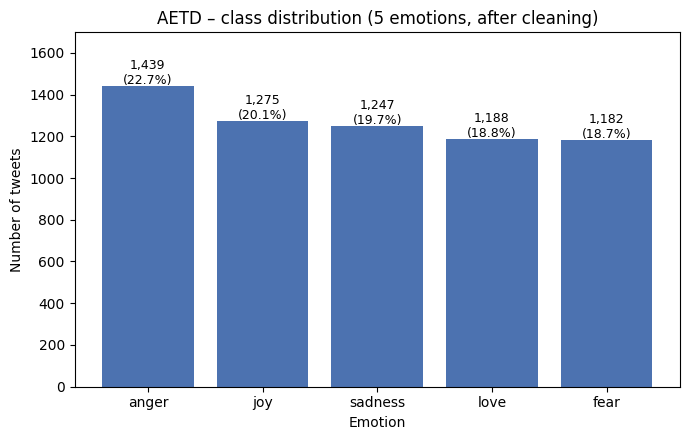

In [63]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(class_table.index, class_table["count"], color="#4C72B0")
for b, pct in zip(bars, class_table["percent"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 10, f"{int(b.get_height()):,}\n({pct:.1f}%)", ha="center", fontsize=9)
ax.set_title("AETD – class distribution (5 emotions, after cleaning)")
ax.set_xlabel("Emotion"); ax.set_ylabel("Number of tweets")
ax.set_ylim(0, class_table["count"].max() * 1.18)
plt.tight_layout(); plt.savefig(FIGS / "class_distribution.png", dpi=200); plt.show()

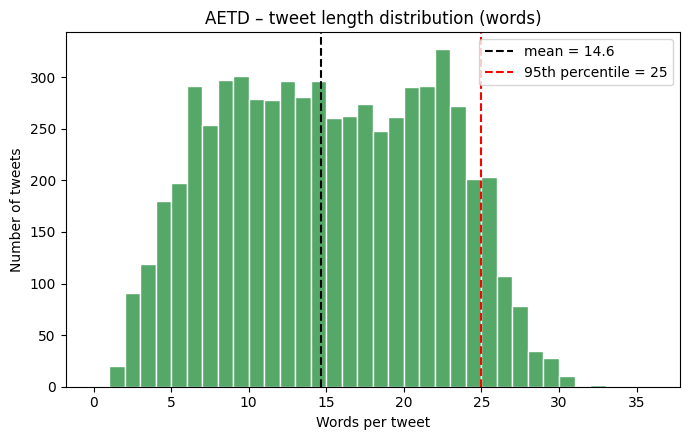

In [64]:
mean_w, p95_w = final["n_words"].mean(), final["n_words"].quantile(0.95)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(final["n_words"], bins=range(0, int(final["n_words"].max()) + 2, 1), color="#55A868", edgecolor="white")
ax.axvline(mean_w, color="black", linestyle="--", label=f"mean = {mean_w:.1f}")
ax.axvline(p95_w, color="red", linestyle="--", label=f"95th percentile = {p95_w:.0f}")
ax.set_title("AETD – tweet length distribution (words)")
ax.set_xlabel("Words per tweet"); ax.set_ylabel("Number of tweets"); ax.legend()
plt.tight_layout(); plt.savefig(FIGS / "tweet_length_distribution.png", dpi=200); plt.show()

## 12. Is the dataset balanced? Do we need stratification?
We look at the class table above: the ratio between the largest and smallest class is small, so the dataset is **roughly balanced**, not perfectly. Even a mild difference matters when we cut the data into three parts: a plain random split could by chance give the test set a slightly different class mix than the training set. **Stratified splitting** cuts each class separately in the same 70/15/15 proportions, so every subset keeps the same class percentages. We use it even though the data is nearly balanced, because it costs nothing and the paper's task is a 5-class problem where per-class precision and recall are reported.

## 13. Stratified train / validation / test split (70 / 15 / 15)
Two calls to `train_test_split`:
1. 70% train, 30% temporary (stratified on `LABEL`)
2. The temporary 30% is cut in half: 15% validation, 15% test (stratified again)

Both use the same `SEED`, so anyone running this notebook gets the **same** files.
Duplicates were removed *before* this point and are **not** touched after the split.

In [65]:
train_df, temp_df = train_test_split(final, test_size=VAL_FRAC + TEST_FRAC, stratify=final["LABEL"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), stratify=temp_df["LABEL"], random_state=SEED)

splits = {"train": train_df, "validation": val_df, "test": test_df}
for name, part in splits.items():
    print(f"{name:<11} {len(part):>5,}  ({len(part) / len(final):.2%})")

train       4,431  (69.99%)
validation    950  (15.01%)
test          950  (15.01%)


## 14. Split verification checklist
Each check is an `assert`, so the notebook stops with an error if something is wrong.

In [66]:
checks = []

# 1) sizes add up and match the target proportions (within 1 tweet of rounding)
assert sum(len(p) for p in splits.values()) == len(final)
checks.append(("Sizes add up to the full dataset", True))
for name, frac in [("train", TRAIN_FRAC), ("validation", VAL_FRAC), ("test", TEST_FRAC)]:
    assert abs(len(splits[name]) - frac * len(final)) <= 2, name
checks.append(("Subset sizes match 70/15/15 (±2 tweets)", True))

# 2) class distribution per subset
dist = pd.DataFrame({n: p["LABEL"].value_counts(normalize=True).reindex(KEEP) * 100 for n, p in splits.items()})
dist["full dataset"] = final["LABEL"].value_counts(normalize=True).reindex(KEEP) * 100
assert (dist.sub(dist["full dataset"], axis=0).abs().max().max()) < 0.5
checks.append(("Class percentages in every subset within 0.5 points of the full dataset", True))

# 3) no overlapping IDs
ids = {n: set(p["ID"]) for n, p in splits.items()}
assert not (ids["train"] & ids["validation"]) and not (ids["train"] & ids["test"]) and not (ids["validation"] & ids["test"])
checks.append(("No ID appears in two subsets", True))

# 4) no identical or near-identical text across subsets
norms = {n: set(p["TWEET"].map(normalize_for_dedup)) for n, p in splits.items()}
assert not (norms["train"] & norms["validation"]) and not (norms["train"] & norms["test"]) and not (norms["validation"] & norms["test"])
checks.append(("No text (exact or normalized) appears in two subsets", True))
for n, p in splits.items():
    assert not p["TWEET"].duplicated().any()
checks.append(("No duplicate tweets inside any subset", True))

# 5) reproducibility: repeat the split with the same seed
t2, tmp2 = train_test_split(final, test_size=VAL_FRAC + TEST_FRAC, stratify=final["LABEL"], random_state=SEED)
v2, te2 = train_test_split(tmp2, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), stratify=tmp2["LABEL"], random_state=SEED)
assert list(t2["ID"]) == list(train_df["ID"]) and list(v2["ID"]) == list(val_df["ID"]) and list(te2["ID"]) == list(test_df["ID"])
checks.append(("Re-running the split with the same seed gives identical files", True))

print(pd.DataFrame(checks, columns=["check", "passed"]).to_string(index=False))
print()
dist.round(2)

                                                                  check  passed
                                       Sizes add up to the full dataset    True
                                Subset sizes match 70/15/15 (±2 tweets)    True
Class percentages in every subset within 0.5 points of the full dataset    True
                                           No ID appears in two subsets    True
                   No text (exact or normalized) appears in two subsets    True
                                  No duplicate tweets inside any subset    True
          Re-running the split with the same seed gives identical files    True



,train,validation,test,full dataset
LABEL,,,,
anger,22.73,22.74,22.74,22.73
joy,20.13,20.21,20.11,20.14
sadness,19.70,19.68,19.68,19.70
love,18.78,18.74,18.74,18.76
fear,18.66,18.63,18.74,18.67


## 15. Saving the final files
Tweet text is saved **unchanged** (only the three columns `ID, TWEET, LABEL`), UTF-8 without BOM so `pd.read_csv(path)` works for everyone.

In [67]:
cols = ["ID", "TWEET", "LABEL"]
final[cols].to_csv(OUT / "aetd_5class_clean.csv", index=False, encoding="utf-8")
train_df[cols].to_csv(OUT / "train.csv", index=False, encoding="utf-8")
val_df[cols].to_csv(OUT / "validation.csv", index=False, encoding="utf-8")
test_df[cols].to_csv(OUT / "test.csv", index=False, encoding="utf-8")

# statistics files
class_table.to_csv(STATS / "class_distribution.csv")
length_table.to_csv(STATS / "tweet_length_stats.csv")
log_df.to_csv(STATS / "cleaning_log.csv", index=False)
split_table = pd.DataFrame({n: p["LABEL"].value_counts().reindex(KEEP) for n, p in splits.items()})
split_table.loc["TOTAL"] = split_table.sum()
split_table.to_csv(STATS / "split_class_counts.csv")

summary = {
    "dataset": "AETD - Arabic Egyptian Twitter Emotion Dataset (Al-Khatib & El-Beltagy, CICLing 2017)",
    "source": "https://github.com/amrmalkhatib/Emotional-Tone",
    "random_seed": SEED,
    "split": {"train": TRAIN_FRAC, "validation": VAL_FRAC, "test": TEST_FRAC, "stratified_on": "LABEL", "method": "sklearn.model_selection.train_test_split, called twice"},
    "original_rows": int(len(raw)),
    "final_rows": int(len(final)),
    "classes": KEEP,
    "class_counts": {k: int(v) for k, v in class_table["count"].items()},
    "subset_sizes": {n: int(len(p)) for n, p in splits.items()},
    "tweet_length_words": {k: float(v) for k, v in length_table["words"].items()},
    "cleaning_log": log,
    "library_versions": {"pandas": pd.__version__, "numpy": np.__version__},
}
(STATS / "dataset_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved:", sorted(p.name for p in OUT.iterdir()), sorted(p.name for p in STATS.iterdir()), sep="\n")

Saved:
['aetd_5class_clean.csv', 'test.csv', 'train.csv', 'validation.csv']
['class_distribution.csv', 'cleaning_log.csv', 'dataset_summary.json', 'split_class_counts.csv', 'tweet_length_stats.csv']


## 16. Final summary

In [68]:
print(f"Seed: {SEED}")
print(f"Original tweets: {len(raw):,}  ->  final clean tweets: {len(final):,}")
print()
print(log_df.to_string(index=False))
print()
print(split_table.to_string())
print()
print(class_table.to_string())

Seed: 42
Original tweets: 10,065  ->  final clean tweets: 6,331

                                          step  rows_after  rows_removed
                                 Original file       10065             0
                               Keep 5 emotions        6408          3657
                           Remove empty tweets        6407             1
   Remove conflicting-label texts (all copies)        6397            10
      Remove exact duplicates (keep lowest ID)        6387            10
Remove tweets with no text after normalization        6385             2
               Remove near-duplicate conflicts        6385             0
                        Remove near-duplicates        6331            54

         train  validation  test
LABEL                           
anger     1007         216   216
joy        892         192   191
sadness    873         187   187
love       832         178   178
fear       827         177   178
TOTAL     4431         950   950

         cou

**Rules from now on**
- The split files are **final**. Nobody re-splits, re-shuffles, or removes rows from train/validation/test.
- The **test set** is used once, for the final evaluation. All tuning (including the bonus idea) uses validation only.
